<a href="https://colab.research.google.com/github/jegedeolakunle21-art/OpenThermoAI/blob/main/OpenThermalAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#install libraries
%pip install -q numpy pandas scikit-learn matplotlib joblib

In [2]:
import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)

PROJECT_DIR = Path("/content/OpenThermoAI")
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [DATA_DIR, MODEL_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("OpenThermoAI folders created.")

OpenThermoAI folders created.


In [3]:
#generate synthetic dataset
def friction_factor(reynolds):
    """Darcy friction factor for smooth pipes."""
    reynolds = np.maximum(np.asarray(reynolds, dtype=float), 1.0)
    return np.where(
        reynolds < 2300,
        64.0 / reynolds,
        0.3164 / np.power(reynolds, 0.25)
    )


def generate_dataset(n=5000, seed=42):
    rng = np.random.default_rng(seed)

    # Operating conditions
    Th_in = rng.uniform(65, 110, n)       # deg C
    Tc_in = rng.uniform(15, 35, n)        # deg C
    mdot_h = rng.uniform(0.15, 2.0, n)    # kg/s
    mdot_c = rng.uniform(0.15, 2.0, n)    # kg/s

    area = rng.uniform(2.0, 20.0, n)     # m^2
    U = rng.uniform(250, 1200, n)        # W/(m^2 K)
    Dh_h = rng.uniform(0.008, 0.025, n)  # m
    Dh_c = rng.uniform(0.008, 0.025, n)  # m
    L_h = rng.uniform(2.0, 12.0, n)      # m
    L_c = rng.uniform(2.0, 12.0, n)      # m

    # Approximate water properties
    rho_h, rho_c = 983.0, 997.0          # kg/m^3
    cp_h, cp_c = 4180.0, 4180.0          # J/(kg K)
    mu_h, mu_c = 0.00047, 0.00089        # Pa s
    k_h, k_c = 0.65, 0.60                # W/(m K)

    # Flow area approximated as circular passage area
    Aflow_h = np.pi * Dh_h**2 / 4
    Aflow_c = np.pi * Dh_c**2 / 4

    velocity_h = mdot_h / (rho_h * Aflow_h)
    velocity_c = mdot_c / (rho_c * Aflow_c)

    Re_h = rho_h * velocity_h * Dh_h / mu_h
    Re_c = rho_c * velocity_c * Dh_c / mu_c

    # Effectiveness-NTU for counterflow exchanger
    Ch = mdot_h * cp_h
    Cc = mdot_c * cp_c
    Cmin = np.minimum(Ch, Cc)
    Cmax = np.maximum(Ch, Cc)
    Cr = Cmin / Cmax
    NTU = U * area / Cmin

    eps = np.empty(n)
    equal_capacity = np.isclose(Cr, 1.0, atol=1e-7)

    eps[equal_capacity] = (
        NTU[equal_capacity] / (1.0 + NTU[equal_capacity])
    )

    idx = ~equal_capacity
    exp_term = np.exp(-NTU[idx] * (1.0 - Cr[idx]))
    eps[idx] = (
        (1.0 - exp_term) /
        (1.0 - Cr[idx] * exp_term)
    )

    Q = eps * Cmin * np.maximum(Th_in - Tc_in, 0.0)

    Th_out = Th_in - Q / Ch
    Tc_out = Tc_in + Q / Cc

    # Simplified heat-transfer correlations.
    # Blend laminar and turbulent estimates for numerical continuity.
    Nu_h_lam = np.full(n, 3.66)
    Nu_c_lam = np.full(n, 3.66)

    Pr_h = cp_h * mu_h / k_h
    Pr_c = cp_c * mu_c / k_c

    Nu_h_turb = (
        0.023 * np.maximum(Re_h, 1)**0.8 * Pr_h**0.4
    )
    Nu_c_turb = (
        0.023 * np.maximum(Re_c, 1)**0.8 * Pr_c**0.4
    )

    blend_h = np.clip((Re_h - 2300) / 1700, 0, 1)
    blend_c = np.clip((Re_c - 2300) / 1700, 0, 1)

    Nu_h = (1 - blend_h) * Nu_h_lam + blend_h * Nu_h_turb
    Nu_c = (1 - blend_c) * Nu_c_lam + blend_c * Nu_c_turb

    h_h = Nu_h * k_h / Dh_h
    h_c = Nu_c * k_c / Dh_c

    f_h = friction_factor(Re_h)
    f_c = friction_factor(Re_c)

    # Pressure drop with a simplified minor-loss coefficient K = 2.
    dp_h = (
        f_h * (L_h / Dh_h) + 2.0
    ) * rho_h * velocity_h**2 / 2

    dp_c = (
        f_c * (L_c / Dh_c) + 2.0
    ) * rho_c * velocity_c**2 / 2

    data = pd.DataFrame({
        "Th_in_C": Th_in,
        "Tc_in_C": Tc_in,
        "mdot_h_kg_s": mdot_h,
        "mdot_c_kg_s": mdot_c,
        "area_m2": area,
        "U_W_m2K": U,
        "Dh_h_m": Dh_h,
        "Dh_c_m": Dh_c,
        "L_h_m": L_h,
        "L_c_m": L_c,
        "Re_h": Re_h,
        "Re_c": Re_c,
        "Q_W": Q,
        "Th_out_C": Th_out,
        "Tc_out_C": Tc_out,
        "dp_h_Pa": dp_h,
        "dp_c_Pa": dp_c,
        "Nu_h": Nu_h,
        "Nu_c": Nu_c,
        "h_h_W_m2K": h_h,
        "h_c_W_m2K": h_c
    })

    return data


df = generate_dataset(n=5000, seed=SEED)
df.to_csv(DATA_DIR / "synthetic_heat_exchanger_data.csv", index=False)

display(df.head())
print("Dataset shape:", df.shape)
print("Saved synthetic dataset.")

,Th_in_C,Tc_in_C,mdot_h_kg_s,mdot_c_kg_s,area_m2,U_W_m2K,Dh_h_m,Dh_c_m,L_h_m,L_c_m,...,Re_c,Q_W,Th_out_C,Tc_out_C,dp_h_Pa,dp_c_Pa,Nu_h,Nu_c,h_h_W_m2K,h_c_W_m2K
0,99.828022,19.362984,1.483348,0.792977,15.333910,1156.529190,0.013901,0.010343,4.914198,8.861782,...,109683.935024,255944.598974,58.549249,96.579331,331548.344597,754853.465425,836.904927,513.816764,39132.652015,29807.256079
1,84.749530,28.258554,1.465790,0.340193,19.924516,1190.927939,0.015157,0.010474,3.208365,9.555496,...,46465.093025,80330.474742,71.638635,84.749412,166495.214420,169329.803339,773.539237,258.461166,33172.215626,14805.646161
2,103.636906,30.337230,0.524986,0.708827,2.737592,1041.508110,0.024740,0.013190,3.073729,5.104148,...,76877.916905,97649.358406,59.138388,63.294640,2753.427408,126206.315985,229.890912,386.665244,6040.006478,17588.460890
3,96.381561,18.332723,0.217812,1.642407,6.408550,671.689713,0.009431,0.021032,2.093435,3.619552,...,111717.587209,70037.249477,19.456113,28.534412,31845.180571,55799.249729,245.997638,521.424087,16954.022512,14875.208218
4,69.237981,15.877166,0.712029,1.062937,12.759333,770.038909,0.009898,0.015025,11.783564,4.198358,...,101209.297854,136059.147509,23.523508,46.499894,867932.260994,125398.460806,610.491712,481.803755,40090.608243,19240.402398


Dataset shape: (5000, 21)
Saved synthetic dataset.


In [4]:
#perform datachecks
energy_hot = (
    df["mdot_h_kg_s"] * 4180 *
    (df["Th_in_C"] - df["Th_out_C"])
)

energy_cold = (
    df["mdot_c_kg_s"] * 4180 *
    (df["Tc_out_C"] - df["Tc_in_C"])
)

energy_error = np.abs(energy_hot - energy_cold) / np.maximum(
    np.abs(energy_hot), 1.0
)

checks = {
    "All outputs finite": bool(np.isfinite(df.to_numpy()).all()),
    "Hot outlet below hot inlet": bool(
        (df["Th_out_C"] <= df["Th_in_C"]).all()
    ),
    "Cold outlet above cold inlet": bool(
        (df["Tc_out_C"] >= df["Tc_in_C"]).all()
    ),
    "Cold outlet below hot inlet": bool(
        (df["Tc_out_C"] <= df["Th_in_C"] + 1e-9).all()
    ),
    "Energy balance max relative error < 1e-8": bool(
        energy_error.max() < 1e-8
    ),
    "Positive heat transfer": bool((df["Q_W"] > 0).all()),
    "Positive pressure drops": bool(
        ((df["dp_h_Pa"] > 0) & (df["dp_c_Pa"] > 0)).all()
    )
}

for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), "-", name)

assert all(checks.values()), "An engineering check failed."

PASS - All outputs finite
PASS - Hot outlet below hot inlet
PASS - Cold outlet above cold inlet
PASS - Cold outlet below hot inlet
PASS - Energy balance max relative error < 1e-8
PASS - Positive heat transfer
PASS - Positive pressure drops


In [5]:
# train models
FEATURES = [
    "Th_in_C", "Tc_in_C",
    "mdot_h_kg_s", "mdot_c_kg_s",
    "area_m2", "U_W_m2K",
    "Dh_h_m", "Dh_c_m",
    "L_h_m", "L_c_m"
]

TARGETS = [
    "Q_W", "Th_out_C", "Tc_out_C",
    "dp_h_Pa", "dp_c_Pa",
    "Nu_h", "Nu_c",
    "h_h_W_m2K", "h_c_W_m2K"
]

X = df[FEATURES]
y = df[TARGETS]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

models = {
    "RandomForest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=SEED
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=SEED
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start

    predictions = model.predict(X_test)
    fitted_models[name] = model

    for i, target in enumerate(TARGETS):
        results.append({
            "model": name,
            "target": target,
            "MAE": mean_absolute_error(
                y_test.iloc[:, i], predictions[:, i]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_test.iloc[:, i], predictions[:, i]
            )),
            "R2": r2_score(y_test.iloc[:, i], predictions[:, i]),
            "training_seconds": train_seconds
        })

metrics = pd.DataFrame(results)
metrics.to_csv(REPORT_DIR / "model_validation_metrics.csv", index=False)

display(metrics.round(4))

,model,target,MAE,RMSE,R2,training_seconds
0,RandomForest,Q_W,36739.2266,49877.1244,0.5302,6.2857
1,RandomForest,Th_out_C,9.2409,11.9100,0.5836,6.2857
2,RandomForest,Tc_out_C,8.8526,11.5557,0.6277,6.2857
3,RandomForest,dp_h_Pa,115906.1591,339736.7585,0.8946,6.2857
4,RandomForest,dp_c_Pa,100118.3969,261424.8261,0.9557,6.2857
5,RandomForest,Nu_h,70.3170,108.2722,0.8684,6.2857
6,RandomForest,Nu_c,44.2151,68.5375,0.9204,6.2857
7,RandomForest,h_h_W_m2K,3858.4082,6221.6768,0.9225,6.2857
8,RandomForest,h_c_W_m2K,2127.5659,3304.4864,0.9610,6.2857
9,ExtraTrees,Q_W,36705.2945,49833.7328,0.5310,1.6465


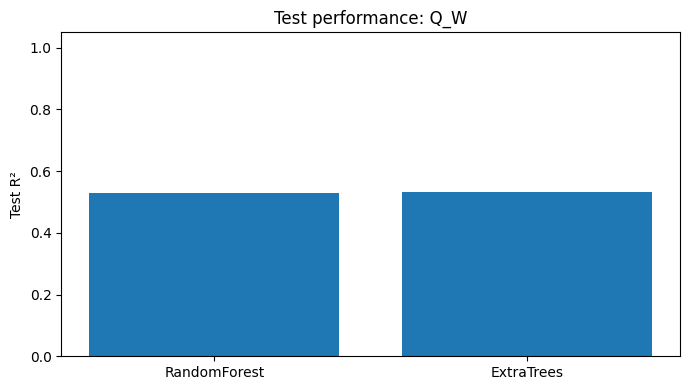

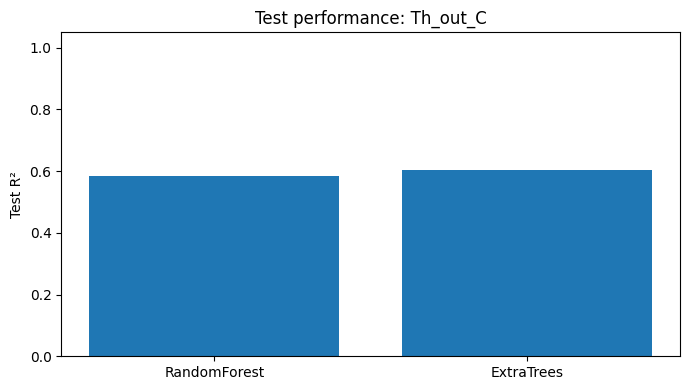

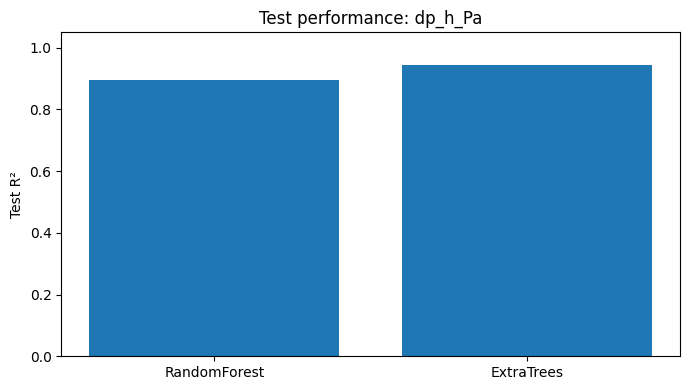

In [6]:
#plot model validation results
for target in ["Q_W", "Th_out_C", "dp_h_Pa"]:
    subset = metrics[metrics["target"] == target]

    plt.figure(figsize=(7, 4))
    plt.bar(subset["model"], subset["R2"])
    plt.ylabel("Test R²")
    plt.title(f"Test performance: {target}")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

In [7]:
# Select the model with the highest mean test R² across targets.
mean_r2 = metrics.groupby("model")["R2"].mean()
best_name = mean_r2.idxmax()
best_model = fitted_models[best_name]

bundle = {
    "model": best_model,
    "features": FEATURES,
    "targets": TARGETS,
    "selected_model": best_name,
    "training_data_type": "synthetic",
    "random_seed": SEED,
    "assumptions": [
        "Single-phase water-to-water exchanger",
        "Constant approximate water properties",
        "Counterflow effectiveness-NTU thermal model",
        "Simplified smooth-pipe friction-factor correlation",
        "Simplified minor-loss coefficient K=2"
    ]
}

joblib.dump(bundle, MODEL_DIR / "openthermoai_model.joblib")

print("Selected model:", best_name)
print("Mean test R²:", round(mean_r2[best_name], 4))
print("Saved model bundle.")

Selected model: ExtraTrees
Mean test R²: 0.8317
Saved model bundle.


In [8]:
#optimize heat transfer performance
def optimize_heat_exchanger(
    model,
    n_candidates=10000,
    max_dp_h=60000,
    max_dp_c=60000,
    max_cold_outlet=60
):
    candidates = pd.DataFrame({
        "Th_in_C": rng.uniform(65, 110, n_candidates),
        "Tc_in_C": rng.uniform(15, 35, n_candidates),
        "mdot_h_kg_s": rng.uniform(0.15, 2.0, n_candidates),
        "mdot_c_kg_s": rng.uniform(0.15, 2.0, n_candidates),
        "area_m2": rng.uniform(2.0, 20.0, n_candidates),
        "U_W_m2K": rng.uniform(250, 1200, n_candidates),
        "Dh_h_m": rng.uniform(0.008, 0.025, n_candidates),
        "Dh_c_m": rng.uniform(0.008, 0.025, n_candidates),
        "L_h_m": rng.uniform(2.0, 12.0, n_candidates),
        "L_c_m": rng.uniform(2.0, 12.0, n_candidates)
    })

    pred = pd.DataFrame(
        model.predict(candidates[FEATURES]),
        columns=TARGETS
    )

    combined = pd.concat(
        [candidates.reset_index(drop=True), pred], axis=1
    )

    feasible = combined[
        (combined["dp_h_Pa"] <= max_dp_h) &
        (combined["dp_c_Pa"] <= max_dp_c) &
        (combined["Tc_out_C"] <= max_cold_outlet) &
        (combined["Tc_out_C"] <= combined["Th_in_C"]) &
        (combined["Th_out_C"] >= combined["Tc_in_C"])
    ].copy()

    if feasible.empty:
        raise ValueError(
            "No feasible candidate. Relax the constraints or expand "
            "the candidate sample."
        )

    return feasible.sort_values("Q_W", ascending=False)


scenarios = optimize_heat_exchanger(best_model)

scenarios.to_csv(
    DATA_DIR / "optimization_scenarios.csv", index=False
)

display(scenarios.head(10))

,Th_in_C,Tc_in_C,mdot_h_kg_s,mdot_c_kg_s,area_m2,U_W_m2K,Dh_h_m,Dh_c_m,L_h_m,L_c_m,Q_W,Th_out_C,Tc_out_C,dp_h_Pa,dp_c_Pa,Nu_h,Nu_c,h_h_W_m2K,h_c_W_m2K
9658,106.902624,21.931412,0.806368,1.748204,16.614221,893.125970,0.016651,0.024415,2.691958,4.636914,218218.743135,35.867628,57.071205,49410.798076,58106.830188,439.182048,480.785290,16528.102797,12558.069299
3112,97.002326,16.050560,1.441060,1.347535,7.739314,719.089770,0.022127,0.022840,3.394554,8.168147,210404.421843,61.446725,59.941510,52064.898660,53284.656551,582.379729,433.433311,17408.444986,11630.419005
6161,90.283113,19.915023,1.052857,1.997936,12.199112,811.573588,0.020066,0.023914,11.126451,4.208236,210351.953530,45.581003,55.240015,57044.682729,59426.428985,498.125351,498.504732,15993.418623,13222.068307
7878,108.673250,18.048649,0.929311,1.517066,16.302846,403.913216,0.022835,0.023191,3.340018,3.157012,210040.171976,48.977555,58.508277,31204.012919,52230.667596,430.785682,461.006641,13160.340421,12140.064892
7631,96.588330,31.515316,0.835665,1.546043,19.328531,1095.976377,0.022924,0.023293,4.418043,3.380290,202115.530489,40.623188,59.685902,29892.324957,53647.574489,400.853319,465.191547,12540.935257,12363.254362
6160,96.020159,18.619665,0.856909,1.780344,18.870455,606.765165,0.023092,0.024657,7.001299,5.734654,197967.557937,42.004590,53.749875,34909.681050,56632.760687,412.496659,489.602012,13017.014988,12685.432115
7413,91.774747,19.889717,0.857305,1.372738,15.113787,1014.269500,0.021383,0.023303,9.389260,4.339013,193038.314684,38.758434,58.900025,30692.245168,43003.924793,394.563318,426.233233,12364.201747,11274.314943
1281,83.390122,27.086069,1.056091,1.478057,19.234626,751.099035,0.023622,0.022734,8.875477,5.052924,190757.462793,42.287382,58.725362,32900.995493,49262.140990,451.918229,446.890809,13267.790062,11977.381371
1924,75.098715,18.815118,1.141859,1.337314,16.734979,1102.143424,0.023335,0.023797,7.995297,2.471189,187061.614194,38.052182,57.363202,35543.561989,39611.833320,467.158488,428.671788,13598.193890,11465.574353
8967,79.371471,25.943873,1.373563,1.432988,13.508615,1076.495033,0.023356,0.024943,2.127941,5.122884,182549.511258,46.459230,57.770781,43771.071768,47495.435118,530.426606,436.140131,15412.737078,11566.033401


In [9]:
#create app.py
app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

BASE = Path(__file__).resolve().parent
MODEL_PATH = BASE / "models" / "openthermoai_model.joblib"
METRICS_PATH = BASE / "reports" / "model_validation_metrics.csv"
SCENARIOS_PATH = BASE / "data" / "optimization_scenarios.csv"

st.set_page_config(
    page_title="OpenThermoAI",
    page_icon="🌡️",
    layout="wide"
)

@st.cache_resource
def load_bundle():
    return joblib.load(MODEL_PATH)

bundle = load_bundle()
model = bundle["model"]
FEATURES = bundle["features"]
TARGETS = bundle["targets"]

st.title("🌡️ OpenThermoAI")
st.subheader("AI-powered heat exchanger prediction and optimization")
st.caption(
    "Prototype using synthetic, physically motivated data. "
    "Not yet validated against experimental or CFD results."
)

with st.sidebar:
    st.header("Operating conditions")

    Th = st.slider("Hot inlet temperature (°C)", 65.0, 110.0, 90.0)
    Tc = st.slider("Cold inlet temperature (°C)", 15.0, 35.0, 25.0)
    mh = st.slider("Hot mass flow (kg/s)", 0.15, 2.0, 0.8)
    mc = st.slider("Cold mass flow (kg/s)", 0.15, 2.0, 0.9)
    area = st.slider("Heat transfer area (m²)", 2.0, 20.0, 10.0)
    U = st.slider("Overall heat transfer coefficient (W/m²K)",
                  250.0, 1200.0, 600.0)
    Dh = st.slider("Hot hydraulic diameter (m)", 0.008, 0.025, 0.015)
    Dc = st.slider("Cold hydraulic diameter (m)", 0.008, 0.025, 0.015)
    Lh = st.slider("Hot flow length (m)", 2.0, 12.0, 6.0)
    Lc = st.slider("Cold flow length (m)", 2.0, 12.0, 6.0)

inputs = pd.DataFrame([{
    "Th_in_C": Th,
    "Tc_in_C": Tc,
    "mdot_h_kg_s": mh,
    "mdot_c_kg_s": mc,
    "area_m2": area,
    "U_W_m2K": U,
    "Dh_h_m": Dh,
    "Dh_c_m": Dc,
    "L_h_m": Lh,
    "L_c_m": Lc
}])[FEATURES]

tab1, tab2, tab3 = st.tabs([
    "Prediction", "Optimization", "Validation & data"
])

with tab1:
    st.header("Predicted thermal and hydraulic performance")

    values = model.predict(inputs)[0]
    pred = dict(zip(TARGETS, values))

    c1, c2, c3 = st.columns(3)
    c1.metric("Heat transfer", f"{pred['Q_W']/1000:.2f} kW")
    c2.metric("Hot outlet", f"{pred['Th_out_C']:.2f} °C")
    c3.metric("Cold outlet", f"{pred['Tc_out_C']:.2f} °C")

    c4, c5, c6 = st.columns(3)
    c4.metric("Hot pressure drop", f"{pred['dp_h_Pa']:.0f} Pa")
    c5.metric("Cold pressure drop", f"{pred['dp_c_Pa']:.0f} Pa")
    c6.metric("Hot-side Nusselt number", f"{pred['Nu_h']:.2f}")

    st.write("All predicted outputs")
    st.dataframe(
        pd.DataFrame({
            "Output": TARGETS,
            "Predicted value": values
        }),
        use_container_width=True
    )

    st.download_button(
        "Download prediction as CSV",
        pd.DataFrame([dict(inputs.iloc[0]), pred]).to_csv(index=False),
        file_name="openthermoai_prediction.csv",
        mime="text/csv"
    )

with tab2:
    st.header("Feasible operating-condition search")

    max_dp_h = st.number_input(
        "Maximum hot-side pressure drop (Pa)",
        min_value=1000, max_value=200000, value=60000
    )
    max_dp_c = st.number_input(
        "Maximum cold-side pressure drop (Pa)",
        min_value=1000, max_value=200000, value=60000
    )
    max_tc = st.number_input(
        "Maximum cold outlet temperature (°C)",
        min_value=30.0, max_value=100.0, value=60.0
    )
    n_candidates = st.select_slider(
        "Number of candidate conditions",
        options=[500, 1000, 2500, 5000, 10000],
        value=2500
    )

    if st.button("Run optimization"):
        rng = np.random.default_rng(42)
        candidates = pd.DataFrame({
            "Th_in_C": rng.uniform(65, 110, n_candidates),
            "Tc_in_C": rng.uniform(15, 35, n_candidates),
            "mdot_h_kg_s": rng.uniform(0.15, 2.0, n_candidates),
            "mdot_c_kg_s": rng.uniform(0.15, 2.0, n_candidates),
            "area_m2": rng.uniform(2.0, 20.0, n_candidates),
            "U_W_m2K": rng.uniform(250, 1200, n_candidates),
            "Dh_h_m": rng.uniform(0.008, 0.025, n_candidates),
            "Dh_c_m": rng.uniform(0.008, 0.025, n_candidates),
            "L_h_m": rng.uniform(2.0, 12.0, n_candidates),
            "L_c_m": rng.uniform(2.0, 12.0, n_candidates)
        })

        outputs = pd.DataFrame(
            model.predict(candidates[FEATURES]),
            columns=TARGETS
        )
        results = pd.concat([candidates, outputs], axis=1)

        feasible = results[
            (results["dp_h_Pa"] <= max_dp_h) &
            (results["dp_c_Pa"] <= max_dp_c) &
            (results["Tc_out_C"] <= max_tc) &
            (results["Tc_out_C"] <= results["Th_in_C"]) &
            (results["Th_out_C"] >= results["Tc_in_C"])
        ].sort_values("Q_W", ascending=False)

        if feasible.empty:
            st.warning(
                "No feasible candidates found. Relax the constraints "
                "or increase the candidate count."
            )
        else:
            st.success(
                f"Found {len(feasible)} feasible candidates."
            )
            st.dataframe(feasible.head(20), use_container_width=True)
            st.metric(
                "Best predicted heat transfer",
                f"{feasible.iloc[0]['Q_W']/1000:.2f} kW"
            )
            st.download_button(
                "Download optimization results",
                feasible.to_csv(index=False),
                file_name="openthermoai_optimization.csv",
                mime="text/csv"
            )

with tab3:
    st.header("Model validation and data")

    st.write("Selected model:", bundle["selected_model"])
    st.write("Training data:", bundle["training_data_type"])

    if METRICS_PATH.exists():
        metrics = pd.read_csv(METRICS_PATH)
        st.dataframe(metrics, use_container_width=True)
        st.download_button(
            "Download validation metrics",
            metrics.to_csv(index=False),
            file_name="model_validation_metrics.csv",
            mime="text/csv"
        )
    else:
        st.info("Validation metrics file not found.")

    st.write("### Model assumptions")
    for item in bundle["assumptions"]:
        st.write("- " + item)

    st.warning(
        "This app uses a surrogate trained on synthetic data. "
        "Do not use its outputs as certified equipment-design values. "
        "Validate against experiments, manufacturer data, or CFD "
        "before engineering deployment."
    )
'''

(PROJECT_DIR / "app.py").write_text(app_code, encoding="utf-8")
print("Created:", PROJECT_DIR / "app.py")

Created: /content/OpenThermoAI/app.py


In [11]:
#create deployment dependencies and documentation
requirements = """streamlit
numpy
pandas
scikit-learn
joblib
"""

(PROJECT_DIR / "requirements.txt").write_text(
    requirements, encoding="utf-8"
)

readme = """# OpenThermoAI

OpenThermoAI is an open-source prototype for AI-assisted heat exchanger
prediction and operating-condition optimization.

## Features
- Predict heat transfer, outlet temperatures, pressure drop, Nusselt
  numbers, and heat-transfer coefficients.
- Compare Random Forest and Extra Trees on held-out synthetic data.
- Search sampled operating conditions subject to pressure-drop and
  temperature constraints.
- Explore model validation metrics through Streamlit.

## Data and limitations
The initial dataset is synthetic and generated using a simplified
counterflow effectiveness-NTU thermal model and simplified hydraulic
correlations. It is not experimental data or validated CFD output.
The model should not be used for certified engineering design.

## Run locally
```bash
pip install -r requirements.txt
streamlit run app.py
```
"""

(PROJECT_DIR / "README.md").write_text(readme, encoding="utf-8")
print("Created:", PROJECT_DIR / "README.md")

Created: /content/OpenThermoAI/README.md


In [13]:
import joblib
import pandas as pd

loaded = joblib.load(MODEL_DIR / "openthermoai_model.joblib")

test_input = X_test.iloc[[0]]
test_prediction = loaded["model"].predict(test_input)[0]

test_results = pd.DataFrame({
    "Output": loaded["targets"],
    "Actual synthetic value": y_test.iloc[0].values,
    "Predicted value": test_prediction
})

display(test_results.round(3))

assert len(test_prediction) == len(TARGETS)
print("Prediction test passed.")

,Output,Actual synthetic value,Predicted value
0,Q_W,158096.785,131191.041
1,Th_out_C,74.212,67.548
2,Tc_out_C,102.289,89.121
3,dp_h_Pa,35327.779,34847.810
4,dp_c_Pa,21210.513,24822.256
5,Nu_h,456.605,460.137
6,Nu_c,226.528,227.485
7,h_h_W_m2K,13354.977,13447.644
8,h_c_W_m2K,7992.418,7928.418


Prediction test passed.


In [14]:
#package the project
import zipfile

# Save the optimization scenarios and validation metrics.
# The CSV files are already created by previous cells.

zip_path = "/content/OpenThermoAI_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in PROJECT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, path.relative_to(PROJECT_DIR.parent))

print("Project archive created:", zip_path)

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR))

Project archive created: /content/OpenThermoAI_Project.zip
README.md
app.py
data/optimization_scenarios.csv
data/synthetic_heat_exchanger_data.csv
models/openthermoai_model.joblib
reports/model_validation_metrics.csv
requirements.txt


In [16]:
#download packaged project zip
from google.colab import files
files.download("/content/OpenThermoAI_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
#test the streamlit
%pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 52.5 MB/s eta 0:00:00


In [ ]:
!streamlit run /content/OpenThermoAI/app.py \
    --server.port 8501 \
    --server.headless true



2026-10-21 20:45:36.463 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.73.218.194:8501

